# S2 — Baseline classifier (real data only)

**Goal:** measure how well a classifier trained on **real images only** recognises each class, especially the rare class **df**. This is the reference that synthetic images must beat in S5. The best model is also kept as the **feature extractor** for the generative-model evaluation.

**Metrics** (on the real test set): **precision, recall and F1** per class and macro-averaged, plus the **confusion matrix**.

**Runs:** 3 strategies × 3 seeds (from `configs/classifier.yaml`):

| strategy | idea |
|---|---|
| `none` | plain cross-entropy: the reference baseline |
| `weighted` | cross-entropy weighted by inverse class frequency |
| `oversample` | the sampler draws rare classes more often |

The best epoch of each run is chosen on the **validation** macro-F1; the test set is used only once at the end.

> Use a GPU (Colab: *Runtime → Change runtime type → GPU*). On a laptop CPU, set `QUICK = True` for a short test.

In [1]:
# --- Setup: works locally (.venv) and on Google Colab ---
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or Path("/content").exists()   # browser or VS Code Colab kernel
if IN_COLAB:
    REPO = "https://github.com/zouhairi1/mini_project_generative_visuelle.git"
    target = Path("/content/mini_project_generative_visuelle")
    if not target.exists():
        subprocess.run(["git", "clone", REPO, str(target)], check=True)
    os.chdir(target)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif Path.cwd().name == "notebooks":
    os.chdir("..")                      # run from the repository root

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
print("Project root:", Path.cwd())

Project root: /content/mini_project_generative_visuelle


In [2]:
import json
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.data import load_split, SHORT_NAMES, SPLITS
from src.train_clf import train_classifier, evaluate, summarize
from src.viz import plot_confusion_matrix
from src.utils import load_config, get_device, ensure_dirs, RESULTS_DIR, CKPT_DIR

QUICK = os.environ.get("QUICK", "0") == "1"   # set QUICK = True for a fast smoke test (1 seed, 2 epochs)

cfg = load_config("classifier")
if QUICK:
    cfg["train"].update(epochs=2, seeds=[0], strategies=["none"])
RARE = cfg["rare_class"]
ensure_dirs()
device = get_device()
print("device:", device, "| train config:", cfg["train"])

(train_x, train_y), (val_x, val_y), (test_x, test_y) = [load_split(s, cfg["data"]["size"]) for s in SPLITS]
print("train", train_x.shape, "| val", val_x.shape, "| test", test_x.shape)

device: cuda | train config: {'epochs': 20, 'lr': 0.001, 'weight_decay': 0.0001, 'seeds': [0, 1, 2], 'strategies': ['none', 'weighted', 'oversample'], 'select_on': 'val_macro_f1'}


100%|██████████| 100M/100M [02:14<00:00, 742kB/s]  


train (7007, 64, 64, 3) | val (1003, 64, 64, 3) | test (2005, 64, 64, 3)


## 1. Training

In [3]:
runs = []
for strategy in cfg["train"]["strategies"]:
    for seed in cfg["train"]["seeds"]:
        model, history = train_classifier(train_x, train_y, val_x, val_y, cfg,
                                          seed=seed, strategy=strategy, device=device)
        runs.append({
            "strategy": strategy,
            "seed": seed,
            "history": history,
            "val": evaluate(model, val_x, val_y, device),
            "test": evaluate(model, test_x, test_y, device),
        })
        torch.save(model.state_dict(), CKPT_DIR / f"clf_{strategy}_seed{seed}.pt")

with open(RESULTS_DIR / "s2_baseline_runs.json", "w") as f:
    json.dump(runs, f, indent=1)

# Reference model (strategy 'none', best validation macro-F1): feature extractor for S5
ref = max((r for r in runs if r["strategy"] == "none"), key=lambda r: r["val"]["macro_f1"])
shutil.copy(CKPT_DIR / f"clf_none_seed{ref['seed']}.pt", CKPT_DIR / "baseline_classifier.pt")
print("Reference model: strategy 'none', seed", ref["seed"], "-> checkpoints/baseline_classifier.pt")

[none | seed 0] epoch  1/20 loss 0.938 | val macro-F1 0.330 | val df recall 0.00 | 6s  *
[none | seed 0] epoch  2/20 loss 0.781 | val macro-F1 0.247 | val df recall 0.00 | 4s
[none | seed 0] epoch  3/20 loss 0.745 | val macro-F1 0.422 | val df recall 0.00 | 4s  *
[none | seed 0] epoch  4/20 loss 0.719 | val macro-F1 0.414 | val df recall 0.00 | 4s
[none | seed 0] epoch  5/20 loss 0.700 | val macro-F1 0.400 | val df recall 0.00 | 4s
[none | seed 0] epoch  6/20 loss 0.676 | val macro-F1 0.448 | val df recall 0.00 | 4s  *
[none | seed 0] epoch  7/20 loss 0.653 | val macro-F1 0.492 | val df recall 0.00 | 4s  *
[none | seed 0] epoch  8/20 loss 0.660 | val macro-F1 0.502 | val df recall 0.00 | 4s  *
[none | seed 0] epoch  9/20 loss 0.635 | val macro-F1 0.515 | val df recall 0.00 | 4s  *
[none | seed 0] epoch 10/20 loss 0.621 | val macro-F1 0.505 | val df recall 0.00 | 4s
[none | seed 0] epoch 11/20 loss 0.606 | val macro-F1 0.482 | val df recall 0.00 | 4s
[none | seed 0] epoch 12/20 loss 0.5

## 2. Results on the test set (mean ± std over seeds)

In [4]:
rows = []
for strategy in cfg["train"]["strategies"]:
    rs = [r["test"] for r in runs if r["strategy"] == strategy]
    rows.append({
        "strategy": strategy,
        "macro precision": summarize([m["macro_precision"] for m in rs]),
        "macro recall": summarize([m["macro_recall"] for m in rs]),
        "macro F1": summarize([m["macro_f1"] for m in rs]),
        "df precision": summarize([m["precision"][RARE] for m in rs]),
        "df recall": summarize([m["recall"][RARE] for m in rs]),
        "df F1": summarize([m["f1"][RARE] for m in rs]),
    })
summary = pd.DataFrame(rows).set_index("strategy")
summary.to_csv(RESULTS_DIR / "s2_summary.csv")
summary

,macro precision,macro recall,macro F1,df precision,df recall,df F1
strategy,,,,,,
none,0.702 ± 0.022,0.565 ± 0.009,0.587 ± 0.006,0.889 ± 0.157,0.116 ± 0.020,0.205 ± 0.036
weighted,0.462 ± 0.006,0.644 ± 0.004,0.507 ± 0.003,0.122 ± 0.007,0.522 ± 0.000,0.198 ± 0.009
oversample,0.551 ± 0.017,0.694 ± 0.013,0.603 ± 0.014,0.394 ± 0.044,0.565 ± 0.071,0.464 ± 0.051


In [5]:
# Per-class precision / recall / F1 (mean over seeds), one block per strategy
blocks = {}
for strategy in cfg["train"]["strategies"]:
    rs = [r["test"] for r in runs if r["strategy"] == strategy]
    blocks[strategy] = pd.DataFrame({
        "precision": np.mean([m["precision"] for m in rs], axis=0),
        "recall": np.mean([m["recall"] for m in rs], axis=0),
        "F1": np.mean([m["f1"] for m in rs], axis=0),
    }, index=SHORT_NAMES)
per_class = pd.concat(blocks, axis=1).round(3)
per_class[("test", "support")] = runs[0]["test"]["support"]
per_class.to_csv(RESULTS_DIR / "s2_per_class.csv")
per_class

none                weighted               oversample         \
      precision recall     F1 precision recall     F1  precision recall   
akiec     0.491  0.505  0.493     0.337  0.712  0.458      0.399  0.662   
bcc       0.586  0.670  0.623     0.455  0.599  0.517      0.529  0.718   
bkl       0.656  0.555  0.600     0.479  0.492  0.485      0.497  0.662   
df        0.889  0.116  0.205     0.122  0.522  0.198      0.394  0.565   
mel       0.569  0.468  0.513     0.335  0.649  0.442      0.399  0.668   
nv        0.876  0.928  0.901     0.959  0.661  0.782      0.963  0.730   
vasc      0.851  0.713  0.775     0.546  0.874  0.671      0.677  0.851   

                test  
          F1 support  
akiec  0.497      66  
bcc    0.609     103  
bkl    0.568     220  
df     0.464      23  
mel    0.498     223  
nv     0.830    1341  
vasc   0.753      29

## 3. Confusion matrices

One matrix per strategy (the seed with the best validation macro-F1). Rows = true class, columns = predicted class. The colour is the **row-normalised** value (= recall of each class); the numbers are image counts.

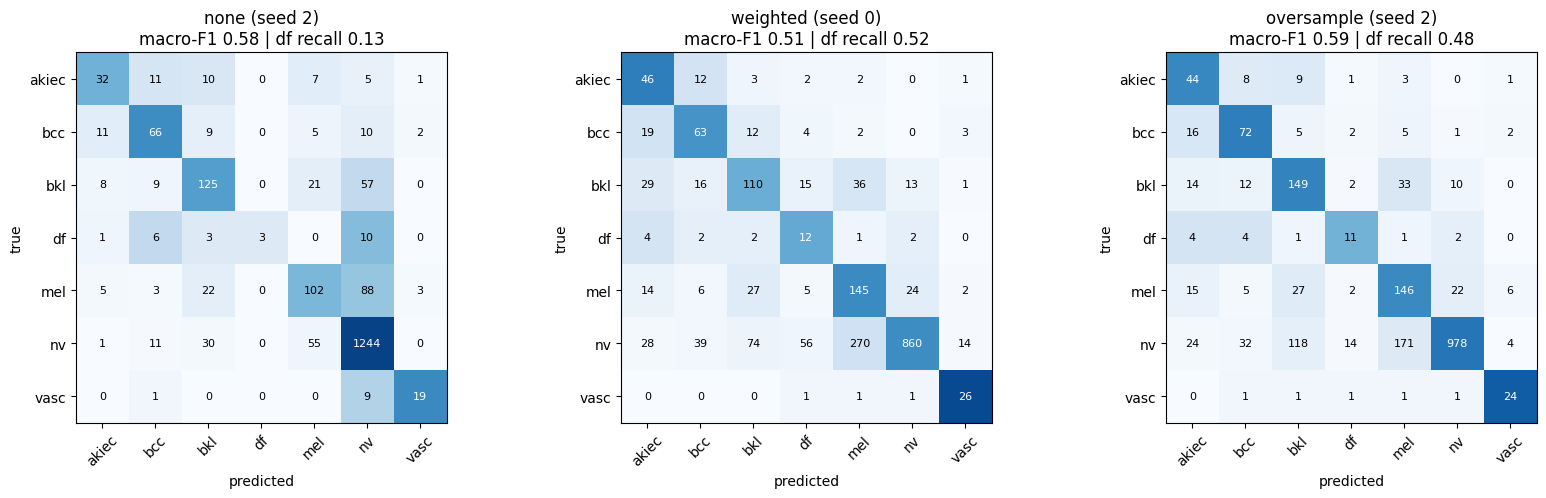

In [6]:
strategies = cfg["train"]["strategies"]
fig, axes = plt.subplots(1, len(strategies), figsize=(5.5 * len(strategies), 5), squeeze=False)
for ax, strategy in zip(axes[0], strategies):
    best = max((r for r in runs if r["strategy"] == strategy), key=lambda r: r["val"]["macro_f1"])
    m = best["test"]
    plot_confusion_matrix(m["confusion_matrix"], ax=ax,
                          title=f"{strategy} (seed {best['seed']})\nmacro-F1 {m['macro_f1']:.2f} | df recall {m['recall'][RARE]:.2f}")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "s2_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Training curves

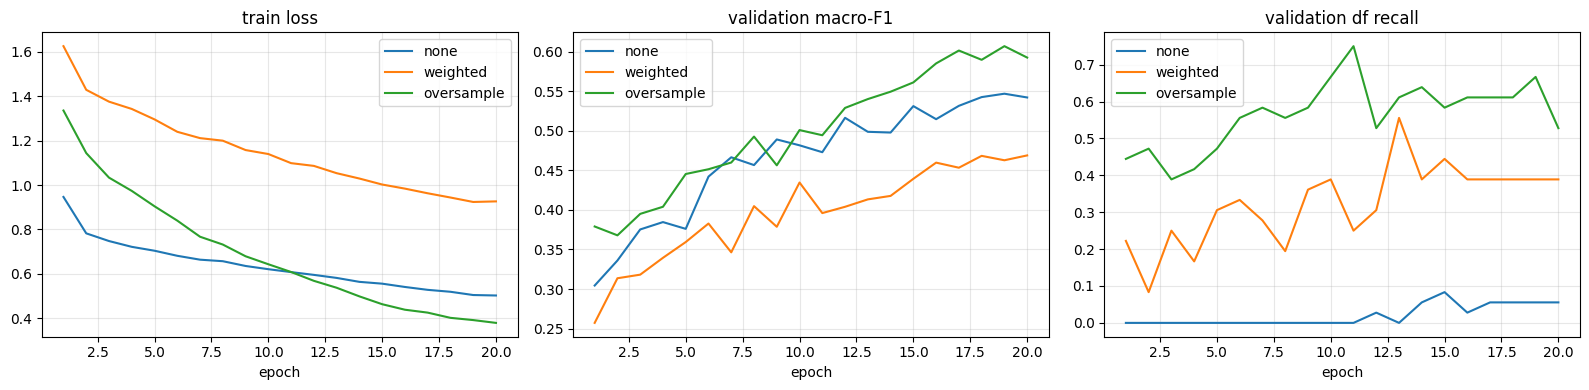

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for strategy in strategies:
    hs = [r["history"] for r in runs if r["strategy"] == strategy]
    epochs = [h["epoch"] for h in hs[0]]
    for ax, key, label in zip(axes, ["train_loss", "val_macro_f1", "val_rare_recall"],
                              ["train loss", "validation macro-F1", "validation df recall"]):
        ax.plot(epochs, np.mean([[h[key] for h in run] for run in hs], axis=0), label=strategy)
        ax.set_title(label)
        ax.set_xlabel("epoch")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "s2_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Interpretation

**Test results (mean ± std over 3 seeds)**

| strategy | macro P | macro R | macro F1 | df precision | df recall | df F1 |
|---|---|---|---|---|---|---|
| none (R0) | **0.702** | 0.565 | 0.587 | **0.889** | 0.116 | 0.205 |
| weighted | 0.462 | 0.644 | 0.507 | 0.122 | 0.522 | 0.198 |
| oversample (R1) | 0.551 | **0.694** | **0.603** | 0.394 | **0.565** | **0.464** |

**1. With real data only (`none`), the model almost ignores the rare class.**
df recall is only **0.116**: on average about 3 of the 23 df test images are found. In the confusion matrix (seed 2), the 23 df images are predicted as nv (10), bcc (6), bkl (3), akiec (1) and only 3 as df. Precision is high (0.889) only because the model almost never predicts df: when it does, it is usually right. This matches S1: df is pale and low-contrast, close to akiec, bcc and the skin itself.

**2. The majority class dominates.** nv has the best F1 (0.90) and is the "default" prediction: it also absorbs **88 of 223 melanomas** (mel recall 0.47). That error is the most serious one medically, since melanoma is the dangerous class. vasc (red/purple, very distinctive) is recognised well despite only 99 training images (F1 0.78).

**3. Class weighting moves the problem instead of solving it.** df recall rises to 0.52, but the model now predicts df far too often (56 nv images predicted as df in the seed-0 matrix), so df precision falls to **0.12** and df F1 does not improve (0.198 vs 0.205). nv recall drops from 0.93 to 0.66 (270 nv → mel), and macro-F1 is the lowest (0.507).

**4. Oversampling gives the best trade-off.** df F1 more than doubles (0.205 → **0.464**) and macro-F1 is the best (0.603), at the cost of nv recall (0.93 → 0.73; nv is now confused with mel and bkl). But oversampling only **repeats the same 80 df images**: the model sees no new variability.

**5. Training curves.** The `none` validation macro-F1 is still rising at epoch 20, so a few more epochs could help it slightly. The validation df recall is very noisy: the val set has only 12 df images, so one image ≈ 8 points. This is why we use 3 seeds and select on macro-F1, not on df recall.

**What S5 must show:** the reference to beat is **R0 = `none`** (df F1 0.205) and the stronger control **R1 = `oversample`** (df F1 0.464). Synthetic images (R2 CVAE, R3 cGAN) are only useful if they bring *new* df variability: they must beat **oversampling**, not just the plain baseline, without destroying nv/mel performance.

## Conclusion of S2
- Reference model saved: `checkpoints/baseline_classifier.pt` (strategy `none`, seed 2, test macro-F1 0.581). Not committed: upload it to Drive. It is the feature extractor for S5.
- Tables and figures in `results/`: `s2_summary.csv`, `s2_per_class.csv`, `s2_confusion_matrices.png`, `s2_training_curves.png`, `s2_baseline_runs.json`.
- Next step: **S3**, the generative models (CVAE and cGAN).


## 6. Bring the results back to your laptop (Colab only)

On Colab (browser or VS Code), the files above are written on Google's machine. This cell zips `results/` and the reference checkpoint and downloads `s2_results.zip`. Unzip it into your local `mini_project/` folder, then commit and push the results.

In [8]:
import zipfile

zip_path = Path("s2_results.zip")
with zipfile.ZipFile(zip_path, "w") as z:
    for p in sorted(RESULTS_DIR.glob("s2_*")):
        z.write(p, p.relative_to(Path.cwd()))
    ref_ckpt = CKPT_DIR / "baseline_classifier.pt"
    if ref_ckpt.exists():
        z.write(ref_ckpt, ref_ckpt.relative_to(Path.cwd()))
print("Created", zip_path.resolve(), "with", len(zipfile.ZipFile(zip_path).namelist()), "files")

if IN_COLAB:
    try:
        from google.colab import files
        files.download(str(zip_path))
    except Exception as e:
        print("Automatic download not available here:", e)
        print("Download the file manually from the Colab file browser:", zip_path.resolve())

Created /content/mini_project_generative_visuelle/s2_results.zip with 6 files


### 6b. VS Code + Colab: export the zip as text

In VS Code, `files.download()` does nothing (it needs the browser). This cell prints the zip as text; VS Code saves it in the local notebook.
Then **save the notebook (Ctrl+S)** and run locally: `python -m src.extract_results notebooks/02_baseline.ipynb`

In [9]:
# VS Code + Colab: print the results zip as text so it is saved in the local notebook file
import base64
from pathlib import Path

zip_path = Path("/content/mini_project_generative_visuelle/s2_results.zip")
if not zip_path.exists():
    zip_path = Path("s2_results.zip")
if zip_path.exists():
    data = zip_path.read_bytes()
    print(f"ZIP_BASE64_START {zip_path.name} {len(data)} bytes")
    print(base64.b64encode(data).decode())
    print("ZIP_BASE64_END")
else:
    print("s2_results.zip not found: the Colab session has ended. Use 'Run All' to run everything again (this cell runs last).")

[5049433 bytes extracted locally with src.extract_results: 6 files]
